# Ejemplo de aplicación: Punto de encuentro entre dos ciudades

Dos grupos de personas, uno de la ciudad A y otro de la ciudad B, necesitan un punto de encuentro común. Cada grupo quiere viajar lo menos posible.

## Características

- Problema del mundo real; generalización en 2-D del MOP1 (Schaffer).
- $P_{true}$ conexo: el segmento recto entre las dos ciudades.
- $PF_{true}$ conexo y convexo.
- 2 variables de decisión, escalable a $n$ dimensiones.

## Definición

$F = (f_1(\mathbf{x}),\, f_2(\mathbf{x}))$, donde $\mathbf{x} = (u, v)$ es el punto de encuentro y

$$
f_1(\mathbf{x}) = (u - a_1)^2 + (v - a_2)^2
$$

$$
f_2(\mathbf{x}) = (u - b_1)^2 + (v - b_2)^2
$$

- $f_1$: distancia de viaje al cuadrado del grupo A.
- $f_2$: distancia de viaje al cuadrado del grupo B.

## Dominio y parámetros

| Símbolo | Valor | Significado |
|---|---|---|
| $u$ | $-10 \le u \le 10$ | coordenada horizontal (unidades de 10 km) |
| $v$ | $-10 \le v \le 10$ | coordenada vertical (unidades de 10 km) |
| $\mathbf{a}$ | $(0, 0)$ | ubicación de la ciudad A |
| $\mathbf{b}$ | $(3, 4)$ | ubicación de la ciudad B |
| $L$ | $\lVert \mathbf{b} - \mathbf{a} \rVert = 5$ | distancia entre las ciudades |

## Solución conocida

**Conjunto de Pareto:** todos los puntos del camino recto entre las ciudades,

$$
\mathbf{x} = \mathbf{a} + t\,(\mathbf{b} - \mathbf{a}), \qquad t \in [0, 1]
$$

**Frente de Pareto:**

$$
f_2 = \left(L - \sqrt{f_1}\right)^2, \qquad f_1 \in [0, L^2] = [0, 25]
$$

**Extremos:**

| Punto de encuentro | $f_1$ | $f_2$ |
|---|---|---|
| Ciudad A, $\mathbf{x} = \mathbf{a}$ | 0 | 25 |
| Ciudad B, $\mathbf{x} = \mathbf{b}$ | 25 | 0 |

## Por qué distancias al cuadrado

Con distancias simples $\lVert \mathbf{x} - \mathbf{a} \rVert$ y $\lVert \mathbf{x} - \mathbf{b} \rVert$, el conjunto de Pareto es el mismo segmento, pero el frente se convierte en la recta $f_1 + f_2 = L$:

- El método de suma ponderada degenera en un frente lineal: según los pesos, devuelve solo los extremos o todos los puntos a la vez.
- La distancia simple no es diferenciable en las propias ciudades, lo que afecta a los métodos basados en gradiente como SLSQP.

Las distancias al cuadrado hacen que el frente sea convexo y suave, y penalizan los viajes largos más que proporcionalmente (cansancio, costo de combustible).

## Configuración para $epsilon$-constraint

- Objetivo: $f_l = f_1$
- Restricción: $f_2(\mathbf{x}) \le \varepsilon$
- Rango: $\varepsilon \in [0, L^2] = [0, 25]$
  - $\varepsilon = 0$ da el punto de encuentro en la ciudad B.
  - $\varepsilon = 25$ da el punto de encuentro en la ciudad A.

## $\epsilon$-Constraint

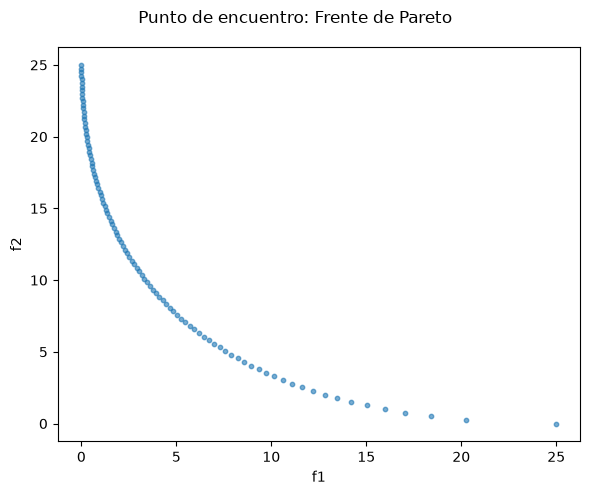

In [4]:
from functions.meetingPoint import MeetingPoint
from utils.graphs import plot_points
from algorithms.epsilonConstraint import EpsilonConstraint
from algorithms.weighting import Weighting
import numpy as np
import time
import json


# a = (0, 0), b = (3, 4) by default
problem = MeetingPoint()                     

problem_bounds = [problem.domain] * problem.n   # [(-10, 10), (-10, 10)]
epsilonConst = EpsilonConstraint(fl=problem.f1, fj=[problem.f2], bounds=problem_bounds, eps_range=(0, problem.L**2), n=problem.n, n_eps_points=100)

inicio = time.perf_counter()
F_points = epsilonConst.run()
fin = time.perf_counter()

graph = plot_points(F_points, names=["f1", "f2"], title="Punto de encuentro: Frente de Pareto", show=True)

## Weighting

Tiempo: 0.039 s | Puntos: 100 | Invocaciones f1: 814, f2: 814


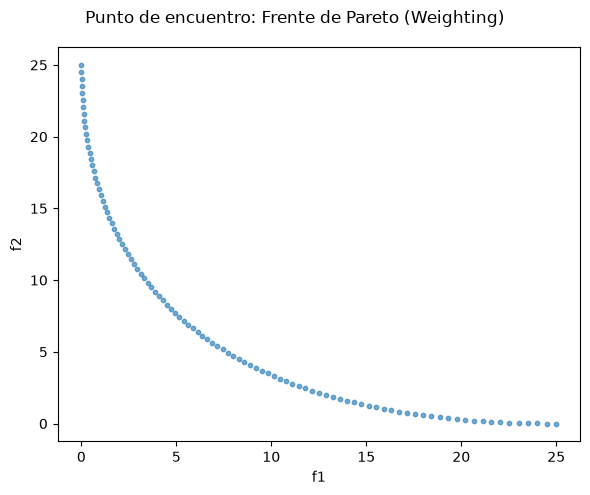

In [5]:
problem = MeetingPoint()

problem_bounds = [problem.domain] * problem.n
weighting = Weighting(fx=[problem.f1, problem.f2], bounds=problem_bounds, n_weights=100)

inicio = time.perf_counter()
F_points = weighting.run()
fin = time.perf_counter()

print(f"Tiempo: {fin - inicio:.3f} s | Puntos: {len(F_points)} | "f"Invocaciones f1: {problem.f1_invok}, f2: {problem.f2_invok}")

graph = plot_points(F_points, names=["f1", "f2"], title="Punto de encuentro: Frente de Pareto (Weighting)", show=True)